In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
df = pd.read_csv("cleaned_invoices.csv")
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (2000000, 35)


,invoice_id,invoice_number,invoice_date,due_date,customer_id,customer_name,customer_email,customer_city,customer_state,customer_country,...,payment_method,payment_status,payment_date,order_channel,sales_rep,is_overdue,delay_days,paid_late_flag,days_to_pay,open_paid_flag
0,2500001,INV-002500001,2025-12-01,2025-12-16,CUST-033946,James Chen,james.chen33946@example.com,Singapore,Singapore,Singapore,...,Upi,Paid,2025-12-05,Online Portal,Rohan Iyer,0,-11.0,0.0,4.0,Paid
1,2500002,INV-002500002,2025-01-04,2025-02-03,CUST-037116,Diya Sharma,diya.sharma37116@example.com,Manchester,England,UK,...,Bank Transfer,Paid,2025-01-25,Marketplace,Karen Kumar,0,-9.0,0.0,21.0,Paid
2,2500003,INV-002500003,2025-07-07,2025-08-06,CUST-027731,Reyansh Nair,reyansh.nair27731@example.com,London,England,UK,...,Upi,Paid,2025-07-21,Phone Order,Richard Miller,0,-16.0,0.0,14.0,Paid
3,2500004,INV-002500004,2025-02-17,2025-03-19,CUST-047646,Arjun Singh,arjun.singh47646@example.com,San Francisco,California,USA,...,Credit Card,Paid,2025-03-11,Walk-In,Krishna Sharma,0,-8.0,0.0,22.0,Paid
4,2500005,INV-002500005,2024-05-09,2024-05-24,CUST-015519,Thomas Wang,thomas.wang15519@example.com,Seattle,Washington,USA,...,Bank Transfer,Overdue,2024-05-24,Sales Rep,Rohan Nair,1,NaN,NaN,NaN,Open



Columns:
['invoice_id', 'invoice_number', 'invoice_date', 'due_date', 'customer_id', 'customer_name', 'customer_email', 'customer_city', 'customer_state', 'customer_country', 'vendor_id', 'vendor_name', 'product_id', 'product_category', 'product_name', 'quantity', 'unit_price', 'discount_percent', 'tax_percent', 'subtotal', 'discount_amount', 'tax_amount', 'shipping_cost', 'total_amount', 'currency', 'payment_method', 'payment_status', 'payment_date', 'order_channel', 'sales_rep', 'is_overdue', 'delay_days', 'paid_late_flag', 'days_to_pay', 'open_paid_flag']


In [3]:
df.columns = df.columns.str.strip()
required_cols = [
    "invoice_date", "due_date", "payment_date",
    "payment_status", "total_amount", "customer_id",
    "customer_name", "customer_country"
]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
 
    raise ValueError(f"Required columns missing from cleaned dataset: {missing_required}")
date_cols = ["invoice_date", "due_date", "payment_date"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

df["payment_status"] = (
    df["payment_status"].astype("string").str.strip().str.lower()
)
numeric_candidates = [
    "total_amount", "subtotal", "tax_amount", "shipping_cost",
    "quantity", "unit_price", "discount_percent", "tax_percent"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Preparation completed.")
print("Rows, columns:", df.shape)
print("\nMissing date values:")
display(df[date_cols].isna().sum())
print("\nPayment status counts:")
display(df["payment_status"].value_counts(dropna=False))


Preparation completed.
Rows, columns: (2000000, 35)

Missing date values:


invoice_date    0
due_date        0
payment_date    0
dtype: int64


Payment status counts:


payment_status
paid         1358819
pending       341015
overdue       199777
cancelled     100389
Name: count, dtype: int64[pyarrow]

In [4]:
paid_mask = (
    df["payment_status"].eq("paid")
    & df["payment_date"].notna()
    & df["due_date"].notna()
)
df["delay_days"] = np.nan
df.loc[paid_mask, "delay_days"] = (
    df.loc[paid_mask, "payment_date"] -
    df.loc[paid_mask, "due_date"]
).dt.days
df["days_to_pay"] = np.nan
valid_days_to_pay = (
    df["payment_status"].eq("paid")
    & df["payment_date"].notna()
    & df["invoice_date"].notna()
)
df.loc[valid_days_to_pay, "days_to_pay"] = (
    df.loc[valid_days_to_pay, "payment_date"] -
    df.loc[valid_days_to_pay, "invoice_date"]
).dt.days
df["payment_category"] = "Not Paid / Not Applicable"
df.loc[paid_mask & (df["delay_days"] > 0), "payment_category"] = "Late Payment"
df.loc[paid_mask & (df["delay_days"] == 0), "payment_category"] = "On-Time Payment"
df.loc[paid_mask & (df["delay_days"] < 0), "payment_category"] = "Early Payment"
df["paid_late_flag"] = pd.Series(pd.NA, index=df.index, dtype="Int64")
df.loc[paid_mask, "paid_late_flag"] = (
    df.loc[paid_mask, "delay_days"] > 0
).astype("int64")

print("PAYMENT DELAY REPORT")
print("--------------------")
print("Total invoices:", len(df))
print("Paid invoices with valid dates:", int(paid_mask.sum()))
print("Late payments:", int((df["payment_category"] == "Late Payment").sum()))
print("On-time payments:", int((df["payment_category"] == "On-Time Payment").sum()))
print("Early payments:", int((df["payment_category"] == "Early Payment").sum()))
print("\nPayment category:")
display(df["payment_category"].value_counts(dropna=False))
print("\nPaid invoice delay statistics:")
display(df.loc[paid_mask, "delay_days"].describe())


PAYMENT DELAY REPORT
--------------------
Total invoices: 2000000
Paid invoices with valid dates: 1358819
Late payments: 0
On-time payments: 53752
Early payments: 1305067

Payment category:


payment_category
Early Payment                1305067
Not Paid / Not Applicable     641181
On-Time Payment                53752
Name: count, dtype: int64


Paid invoice delay statistics:


count    1.358819e+06
mean    -1.501869e+01
std      1.216216e+01
min     -6.000000e+01
25%     -2.200000e+01
50%     -1.200000e+01
75%     -6.000000e+00
max      0.000000e+00
Name: delay_days, dtype: float64

In [5]:
late_paid_records = df.loc[
    paid_mask & (df["delay_days"] > 0),
    ["invoice_id", "invoice_number", "customer_id", "customer_name",
     "invoice_date", "due_date", "payment_date", "delay_days", "payment_status"]
]
print("Paid invoices with payment_date > due_date:", len(late_paid_records))
print("Maximum delay among paid invoices:",
      df.loc[paid_mask, "delay_days"].max())
overdue_status_records = df.loc[
    df["payment_status"].eq("overdue"),
    ["invoice_id", "invoice_date", "due_date", "payment_date", "payment_status"]
]
print("\nOverdue-status rows:", len(overdue_status_records))
print("Overdue-status rows with a payment date:",
      int(overdue_status_records["payment_date"].notna().sum()))
print("Overdue-status rows with payment_date <= due_date:",
      int((overdue_status_records["payment_date"] <= overdue_status_records["due_date"]).sum()))
display(late_paid_records.head(10))
display(overdue_status_records.head(10))

Paid invoices with payment_date > due_date: 0
Maximum delay among paid invoices: 0.0

Overdue-status rows: 199777
Overdue-status rows with a payment date: 199777
Overdue-status rows with payment_date <= due_date: 199777


,invoice_id,invoice_number,customer_id,customer_name,invoice_date,due_date,payment_date,delay_days,payment_status


,invoice_id,invoice_date,due_date,payment_date,payment_status
4,2500005,2024-05-09,2024-05-24,2024-05-24,overdue
5,2500006,2025-01-09,2025-02-08,2025-02-08,overdue
8,2500009,2025-12-06,2026-01-05,2026-01-05,overdue
27,2500028,2024-10-12,2024-11-26,2024-11-26,overdue
51,2500052,2025-03-31,2025-04-30,2025-04-30,overdue
95,2500096,2025-10-28,2025-11-27,2025-11-27,overdue
99,2500100,2025-06-09,2025-06-24,2025-06-24,overdue
103,2500104,2025-07-16,2025-08-15,2025-08-15,overdue
107,2500108,2024-10-26,2024-11-10,2024-11-10,overdue
188,2500189,2025-05-20,2025-06-19,2025-06-19,overdue


In [6]:
print("Duplicate rows:", int(df.duplicated().sum()))
if "invoice_id" in df.columns:
    print("Duplicate invoice IDs:", int(df["invoice_id"].duplicated().sum()))
print("Missing invoice dates:", int(df["invoice_date"].isna().sum()))
print("Missing due dates:", int(df["due_date"].isna().sum()))
print("Missing payment dates:", int(df["payment_date"].isna().sum()))

invalid_due = df["due_date"] < df["invoice_date"]
invalid_payment = df["payment_date"] < df["invoice_date"]
print("Due date earlier than invoice date:", int(invalid_due.sum()))
print("Payment date earlier than invoice date:", int(invalid_payment.sum()))


Duplicate rows: 0
Duplicate invoice IDs: 0
Missing invoice dates: 0
Missing due dates: 0
Missing payment dates: 0
Due date earlier than invoice date: 0
Payment date earlier than invoice date: 0


In [7]:
display(df[["total_amount", "days_to_pay", "delay_days"]].describe().T)


,count,mean,std,min,25%,50%,75%,max
total_amount,2000000.0,33979.163457,29899.385726,4.71,9485.37,25352.21,51494.7225,159936.0
days_to_pay,1358819.0,15.003792,12.136430,0.00,6.00,12.00,22.0000,60.0
delay_days,1358819.0,-15.018694,12.162159,-60.00,-22.00,-12.00,-6.0000,0.0


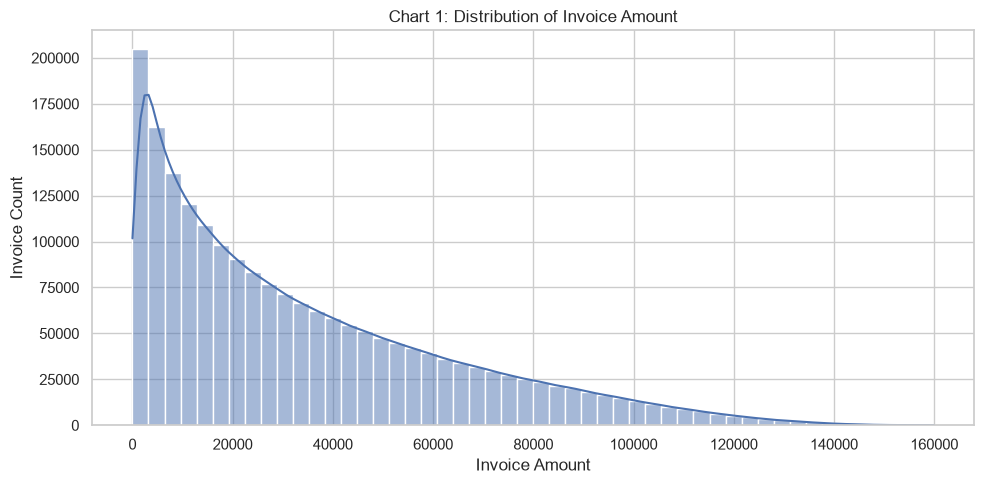

In [8]:
amounts = df["total_amount"].dropna()
plt.figure(figsize=(10, 5))
sns.histplot(amounts, bins=50, kde=True)
plt.title("Chart 1: Distribution of Invoice Amount")
plt.xlabel("Invoice Amount")
plt.ylabel("Invoice Count")
plt.tight_layout()
plt.show()


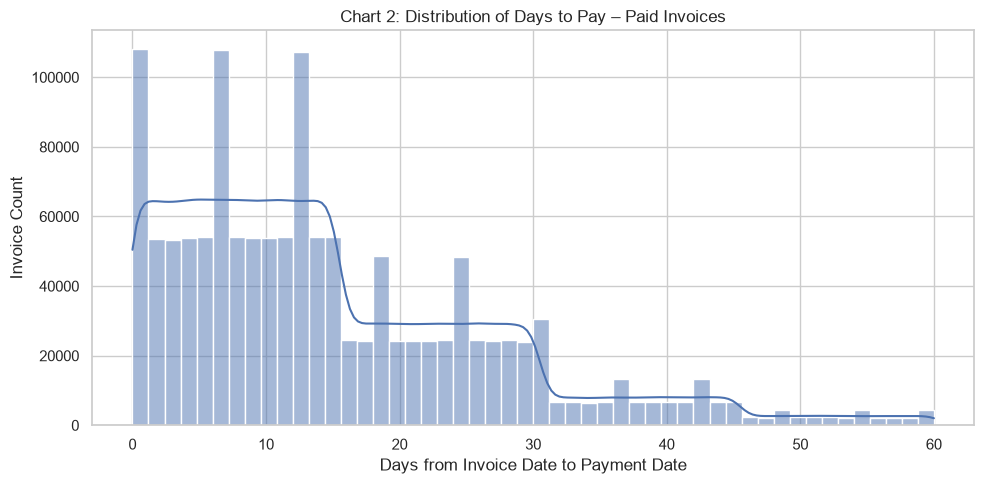

In [9]:
plt.figure(figsize=(10, 5))
sns.histplot(df.loc[valid_days_to_pay, "days_to_pay"].dropna(), bins=50, kde=True)
plt.title("Chart 2: Distribution of Days to Pay – Paid Invoices")
plt.xlabel("Days from Invoice Date to Payment Date")
plt.ylabel("Invoice Count")
plt.tight_layout()
plt.show()


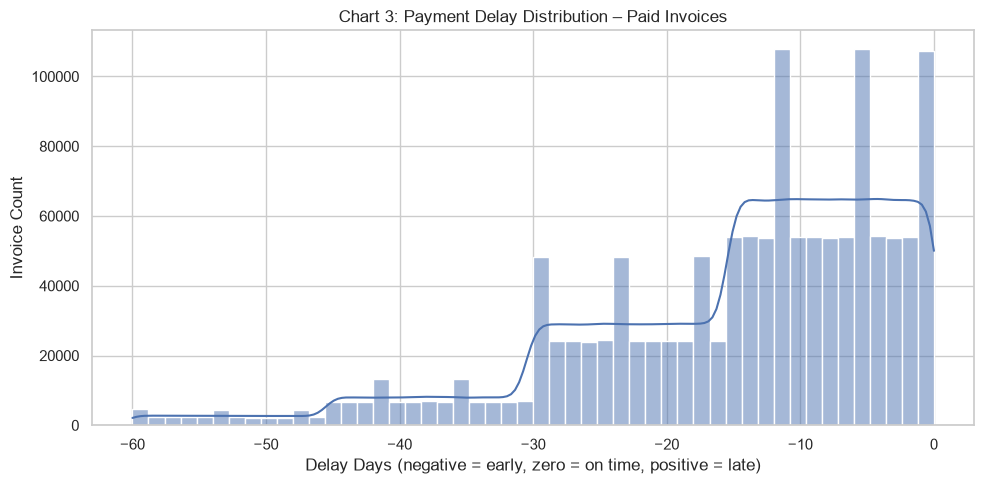

In [10]:
paid_delays = df.loc[paid_mask, "delay_days"].dropna()
plt.figure(figsize=(10, 5))
if len(paid_delays):
    sns.histplot(paid_delays, bins=50, kde=True)
else:
    plt.text(0.5, 0.5, "No valid paid-invoice delay data", ha="center", va="center")
plt.title("Chart 3: Payment Delay Distribution – Paid Invoices")
plt.xlabel("Delay Days (negative = early, zero = on time, positive = late)")
plt.ylabel("Invoice Count")
plt.tight_layout()
plt.show()


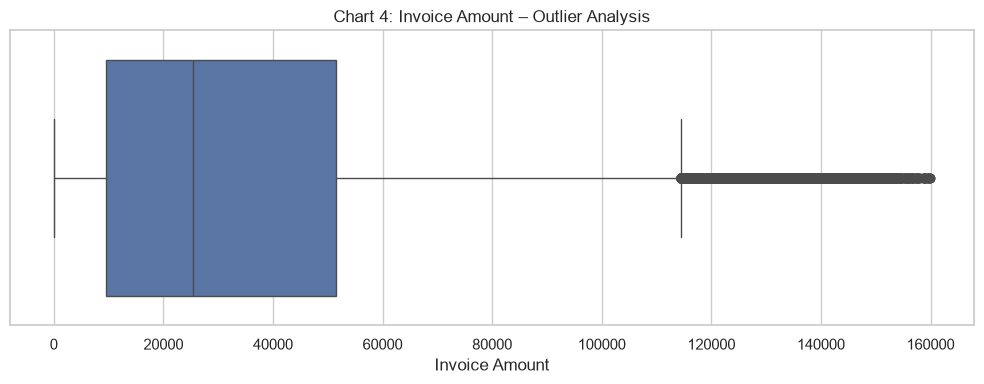

In [11]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["total_amount"].dropna())
plt.title("Chart 4: Invoice Amount – Outlier Analysis")
plt.xlabel("Invoice Amount")
plt.tight_layout()
plt.show()


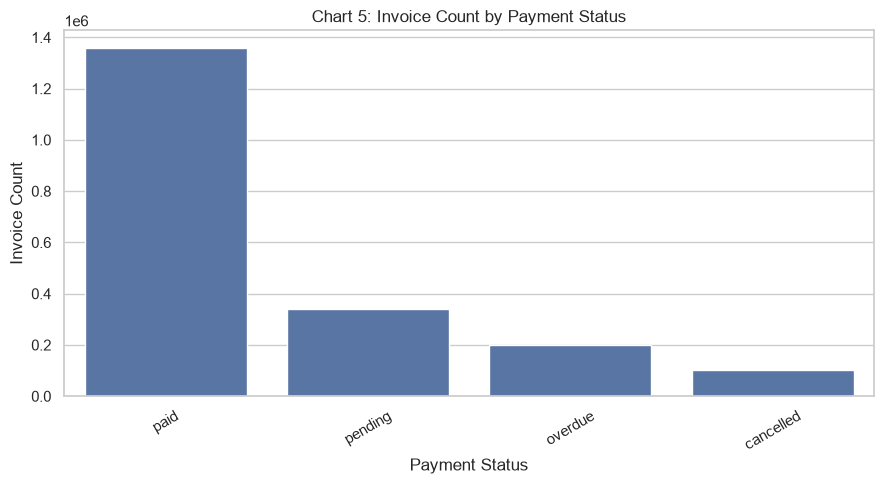

In [12]:
status_counts = df["payment_status"].value_counts()
plt.figure(figsize=(9, 5))
sns.barplot(x=status_counts.index.astype(str), y=status_counts.values)
plt.title("Chart 5: Invoice Count by Payment Status")
plt.xlabel("Payment Status")
plt.ylabel("Invoice Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


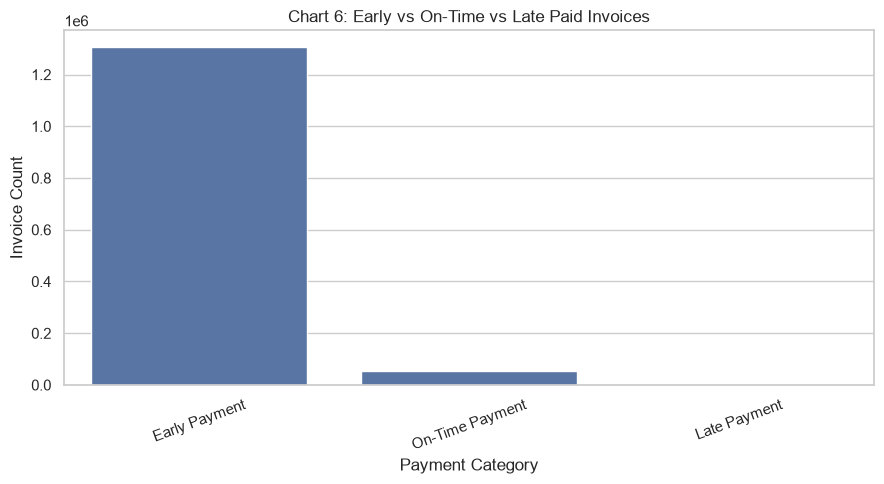

In [13]:
category_order = ["Early Payment", "On-Time Payment", "Late Payment"]
category_counts = df.loc[paid_mask, "payment_category"].value_counts().reindex(category_order, fill_value=0)
plt.figure(figsize=(9, 5))
sns.barplot(x=category_counts.index, y=category_counts.values)
plt.title("Chart 6: Early vs On-Time vs Late Paid Invoices")
plt.xlabel("Payment Category")
plt.ylabel("Invoice Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


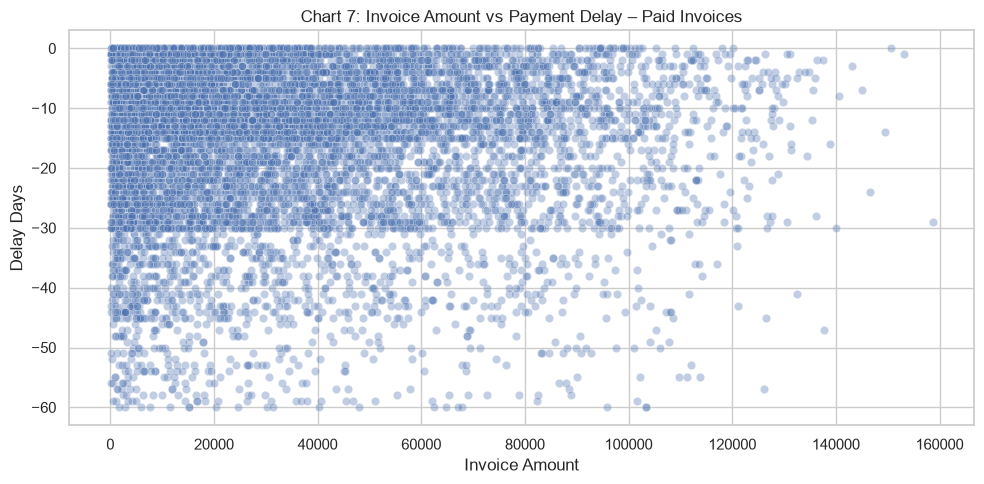

In [14]:
scatter_data = df.loc[paid_mask, ["total_amount", "delay_days"]].dropna()
if len(scatter_data) > 10000:
    scatter_data = scatter_data.sample(10000, random_state=42)
plt.figure(figsize=(10, 5))
if len(scatter_data):
    sns.scatterplot(data=scatter_data, x="total_amount", y="delay_days", alpha=0.35)
else:
    plt.text(0.5, 0.5, "No paid invoice delay observations", ha="center", va="center")
plt.title("Chart 7: Invoice Amount vs Payment Delay – Paid Invoices")
plt.xlabel("Invoice Amount")
plt.ylabel("Delay Days")
plt.tight_layout()
plt.show()


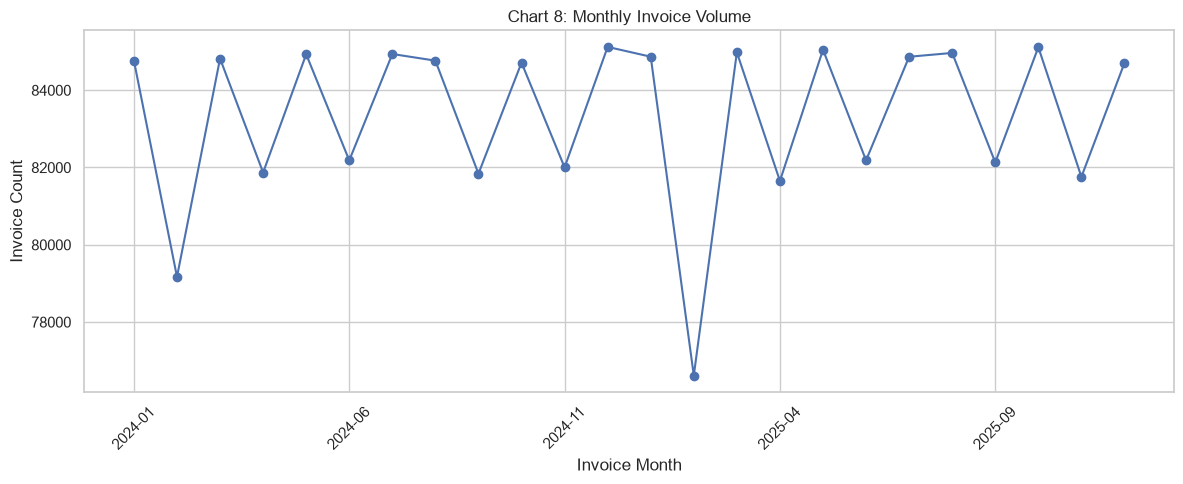

In [15]:
df["invoice_month"] = df["invoice_date"].dt.to_period("M").astype("string")
monthly_volume = df.groupby("invoice_month").size()
plt.figure(figsize=(12, 5))
monthly_volume.plot(marker="o")
plt.title("Chart 8: Monthly Invoice Volume")
plt.xlabel("Invoice Month")
plt.ylabel("Invoice Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


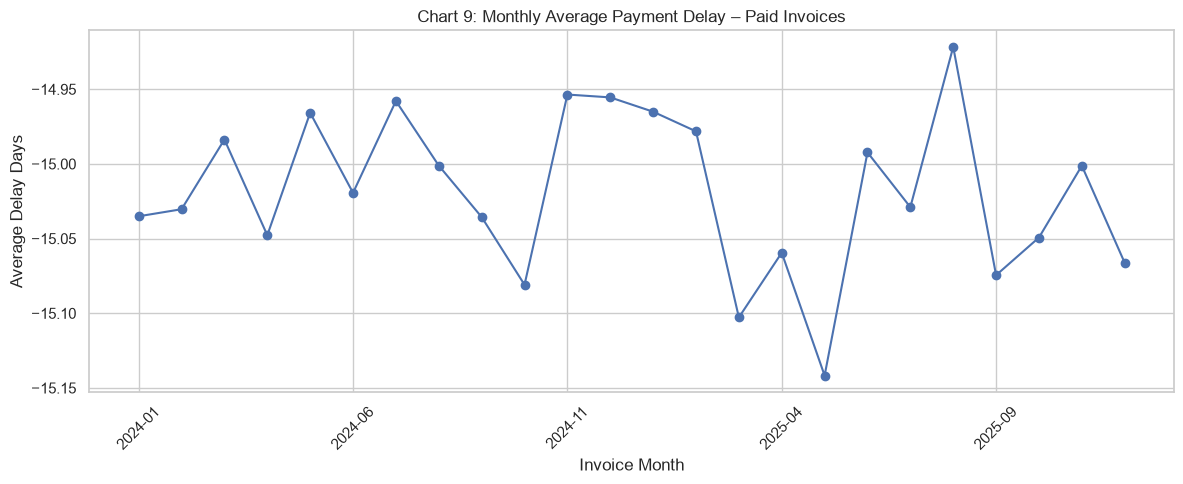

In [16]:
paid_monthly = df.loc[paid_mask].copy()
paid_monthly["invoice_month"] = paid_monthly["invoice_date"].dt.to_period("M").astype("string")
monthly_paid_delay = paid_monthly.groupby("invoice_month")["delay_days"].mean()
plt.figure(figsize=(12, 5))
monthly_paid_delay.plot(marker="o")
plt.title("Chart 9: Monthly Average Payment Delay – Paid Invoices")
plt.xlabel("Invoice Month")
plt.ylabel("Average Delay Days")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


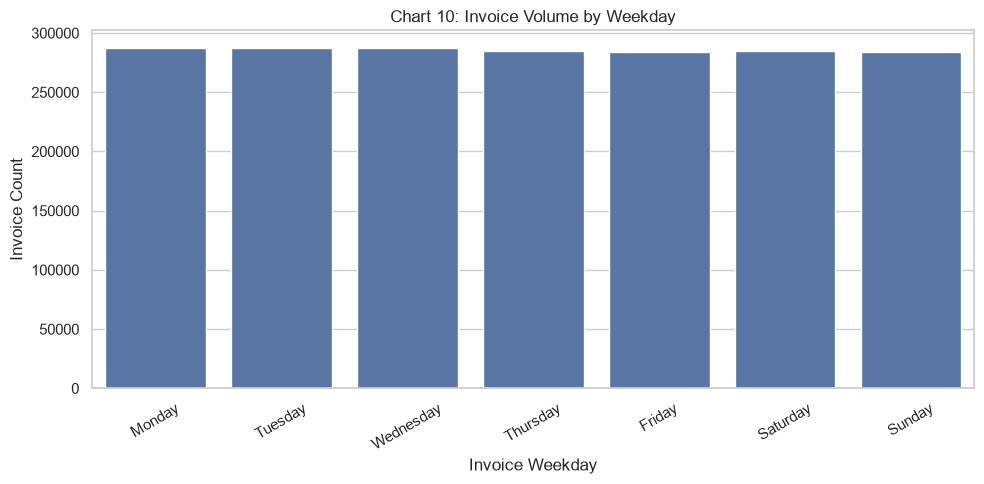

In [17]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["invoice_weekday"] = df["invoice_date"].dt.day_name()
weekday_counts = df["invoice_weekday"].value_counts().reindex(weekday_order)
plt.figure(figsize=(10, 5))
sns.barplot(x=weekday_counts.index, y=weekday_counts.values)
plt.title("Chart 10: Invoice Volume by Weekday")
plt.xlabel("Invoice Weekday")
plt.ylabel("Invoice Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


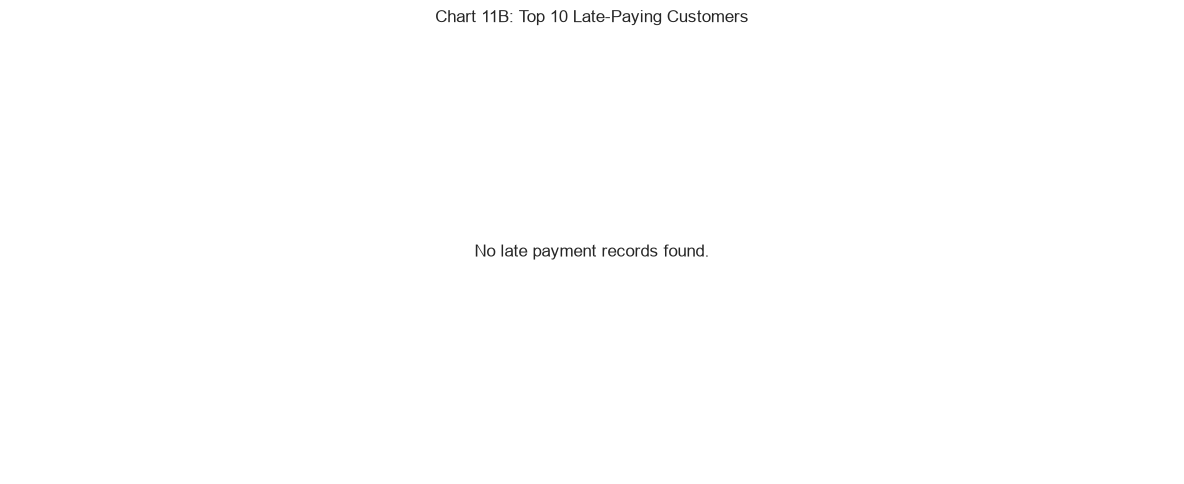

In [30]:
LATE_LABEL="Late Payment"
customer_col = "customer_name" if "customer_name" in df.columns else "customer_id"
late_df = df[df["payment_category"].astype(str).str.strip().str.lower() == LATE_LABEL.lower()]

plt.figure(figsize=(12, 5))
if late_df.empty:
    plt.text(0.5, 0.5, "No late payment records found.",
             ha="center", va="center")
    plt.axis("off")
else:
    top10 = late_df.groupby(customer_col).size().sort_values(ascending=False).head(10)
    top10.sort_values().plot(kind="barh", color="tomato")
    plt.xlabel("Late Paid Invoice Count")
    plt.ylabel("Customer")
plt.title("Chart 11B: Top 10 Late-Paying Customers")
plt.tight_layout()
plt.show()

In [19]:
open_statuses = ["pending", "overdue", "open", "unpaid", "partially paid"]
open_mask = df["payment_status"].isin(open_statuses)
as_of_date = pd.Timestamp.today().normalize()
past_due_mask = open_mask & df["due_date"].notna() & (df["due_date"] < as_of_date)
not_yet_due_mask = open_mask & df["due_date"].notna() & (df["due_date"] >= as_of_date)

print("OVERVIEW METRICS")
print("----------------")
print("As-of date:", as_of_date.date())
print("Total invoices:", len(df))
print("Paid invoices:", int(df["payment_status"].eq("paid").sum()))
print("Outstanding invoices:", int(open_mask.sum()))
print("Past-due outstanding invoices:", int(past_due_mask.sum()))
print("Not-yet-due outstanding invoices:", int(not_yet_due_mask.sum()))
print("Outstanding invoice amount:", round(df.loc[open_mask, "total_amount"].sum(), 2))
print("Past-due outstanding amount:", round(df.loc[past_due_mask, "total_amount"].sum(), 2))


OVERVIEW METRICS
----------------
As-of date: 2026-11-13
Total invoices: 2000000
Paid invoices: 1358819
Outstanding invoices: 540792
Past-due outstanding invoices: 540792
Not-yet-due outstanding invoices: 0
Outstanding invoice amount: 18380053504.35
Past-due outstanding amount: 18380053504.35


In [20]:
df["overdue_days"] = np.nan
df.loc[open_mask & df["due_date"].notna(), "overdue_days"] = (
    as_of_date - df.loc[open_mask & df["due_date"].notna(), "due_date"]
).dt.days

aging_conditions = [
    df["overdue_days"].between(0, 30),
    df["overdue_days"].between(31, 60),
    df["overdue_days"].between(61, 90),
    df["overdue_days"] > 90
]
aging_labels = ["0-30 Days", "31-60 Days", "61-90 Days", "90+ Days"]
df["aging_bucket"] = np.select(aging_conditions, aging_labels, default="Not Due / Unknown")

aging_order = ["0-30 Days", "31-60 Days", "61-90 Days", "90+ Days", "Not Due / Unknown"]
aging_count = (
    df.loc[open_mask, "aging_bucket"]
      .value_counts()
      .reindex(aging_order, fill_value=0)
)
aging_amount = (
    df.loc[open_mask]
      .groupby("aging_bucket")["total_amount"].sum()
      .reindex(aging_order, fill_value=0)
)

print("Invoice aging count:")
display(aging_count)
print("Invoice aging amount:")
display(aging_amount.round(2))


Invoice aging count:


aging_bucket
0-30 Days                 0
31-60 Days                0
61-90 Days                0
90+ Days             540792
Not Due / Unknown         0
Name: count, dtype: int64

Invoice aging amount:


aging_bucket
0-30 Days            0.000000e+00
31-60 Days           0.000000e+00
61-90 Days           0.000000e+00
90+ Days             1.838005e+10
Not Due / Unknown    0.000000e+00
Name: total_amount, dtype: float64

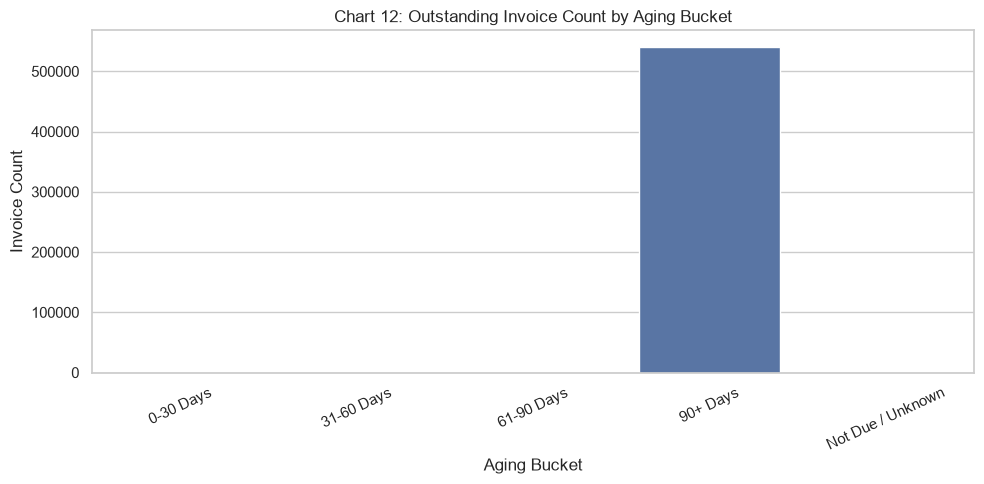

In [21]:
plt.figure(figsize=(10, 5))
sns.barplot(x=aging_count.index, y=aging_count.values)
plt.title("Chart 12: Outstanding Invoice Count by Aging Bucket")
plt.xlabel("Aging Bucket")
plt.ylabel("Invoice Count")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


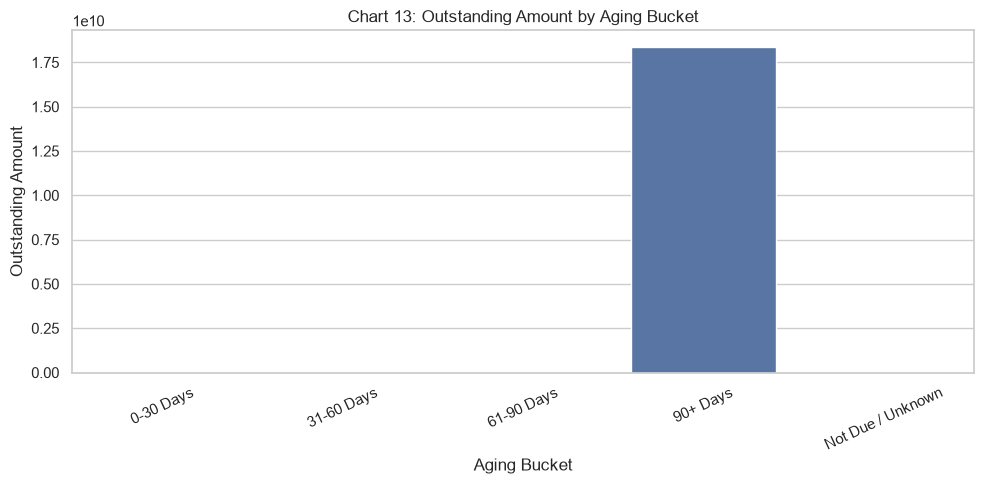

In [22]:
plt.figure(figsize=(10, 5))
sns.barplot(x=aging_amount.index, y=aging_amount.values)
plt.title("Chart 13: Outstanding Amount by Aging Bucket")
plt.xlabel("Aging Bucket")
plt.ylabel("Outstanding Amount")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


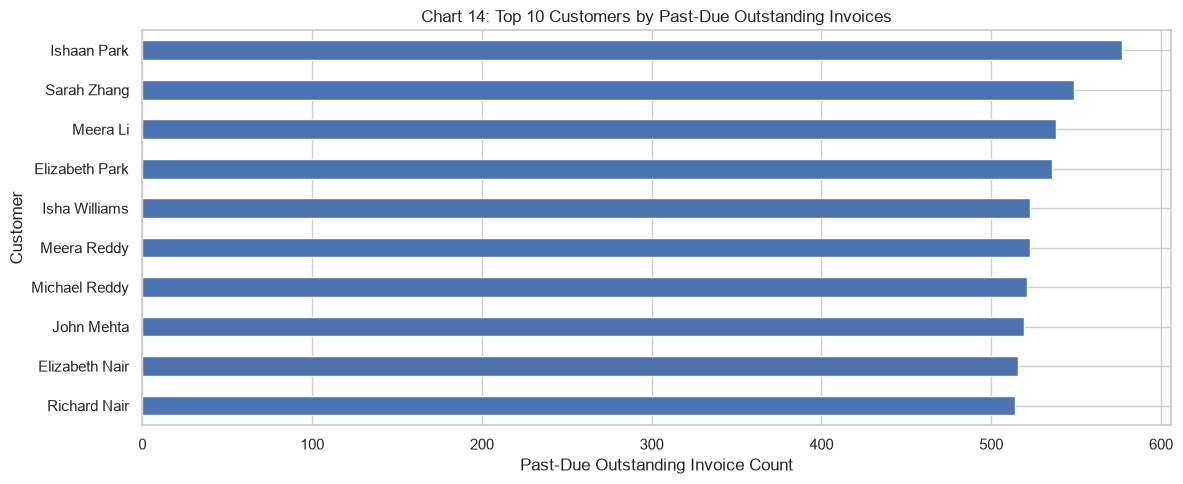

In [23]:
overdue_customer_counts = (
    df.loc[past_due_mask]
      .groupby(customer_col).size()
      .sort_values(ascending=False).head(10)
)
plt.figure(figsize=(12, 5))
if overdue_customer_counts.empty:
    plt.text(0.5, 0.5, "No past-due outstanding invoices found", ha="center", va="center")
    plt.axis("off")
else:
    overdue_customer_counts.sort_values().plot(kind="barh")
    plt.xlabel("Past-Due Outstanding Invoice Count")
    plt.ylabel("Customer")
plt.title("Chart 14: Top 10 Customers by Past-Due Outstanding Invoices")
plt.tight_layout()
plt.show()


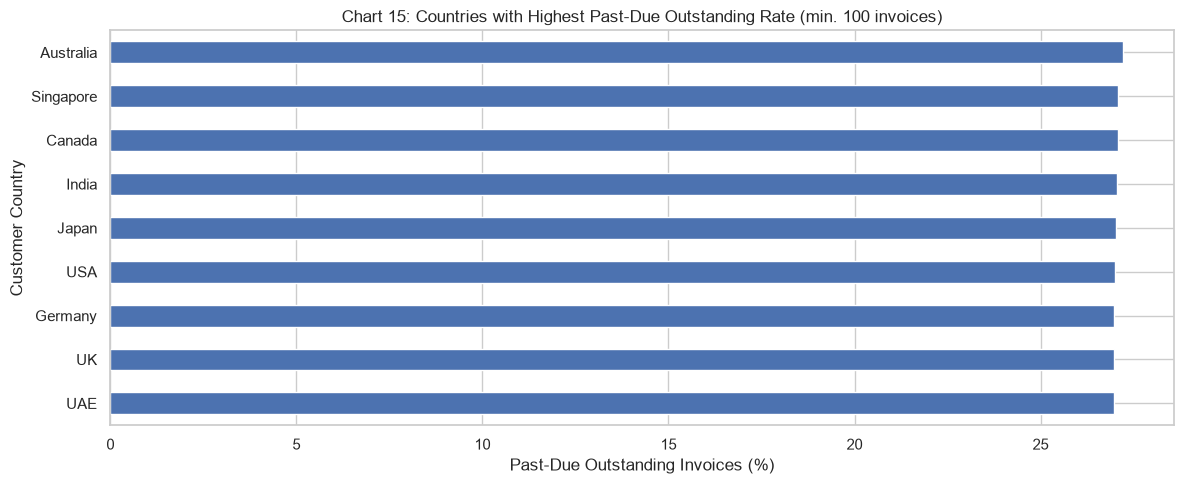

In [24]:
country_col = "customer_country"
country_summary = (
    df.assign(is_past_due=past_due_mask.astype(int))
      .groupby(country_col)
      .agg(invoice_count=("invoice_id", "count"),
           past_due_count=("is_past_due", "sum"))
)
country_summary["past_due_rate_pct"] = (
    country_summary["past_due_count"] / country_summary["invoice_count"] * 100
)
country_summary = country_summary.query("invoice_count >= 100").sort_values(
    "past_due_rate_pct", ascending=False
).head(15)

plt.figure(figsize=(12, 5))
if country_summary.empty:
    plt.text(0.5, 0.5, "Country-level data unavailable", ha="center", va="center")
    plt.axis("off")
else:
    country_summary["past_due_rate_pct"].sort_values().plot(kind="barh")
    plt.xlabel("Past-Due Outstanding Invoices (%)")
    plt.ylabel("Customer Country")
plt.title("Chart 15: Countries with Highest Past-Due Outstanding Rate (min. 100 invoices)")
plt.tight_layout()
plt.show()


Unique customers: 60000
Repeat customers: 60000
Invoices from repeat customers: 2000000


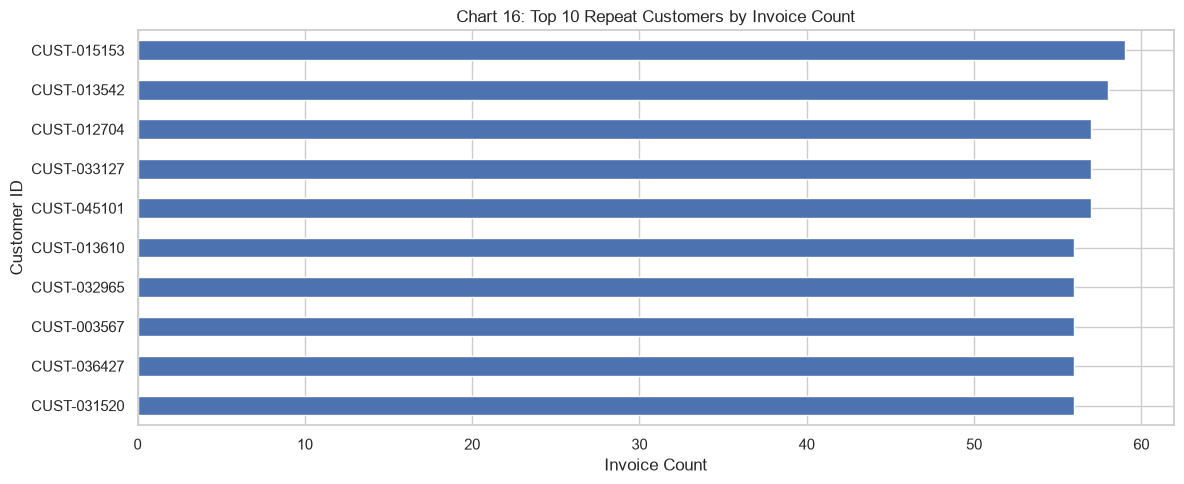

In [25]:
customer_activity = (
    df.groupby("customer_id")
      .agg(invoice_count=("invoice_id", "count"),
           total_invoice_amount=("total_amount", "sum"),
           past_due_count=("invoice_id", lambda x: int(past_due_mask.loc[x.index].sum())))
)
repeat_customers = customer_activity[customer_activity["invoice_count"] > 1]

print("Unique customers:", df["customer_id"].nunique())
print("Repeat customers:", len(repeat_customers))
print("Invoices from repeat customers:",
      int(repeat_customers["invoice_count"].sum()))

top_repeat = repeat_customers.sort_values("invoice_count", ascending=False).head(10)
plt.figure(figsize=(12, 5))
if top_repeat.empty:
    plt.text(0.5, 0.5, "No repeat customers found", ha="center", va="center")
    plt.axis("off")
else:
    top_repeat["invoice_count"].sort_values().plot(kind="barh")
    plt.xlabel("Invoice Count")
    plt.ylabel("Customer ID")
plt.title("Chart 16: Top 10 Repeat Customers by Invoice Count")
plt.tight_layout()
plt.show()


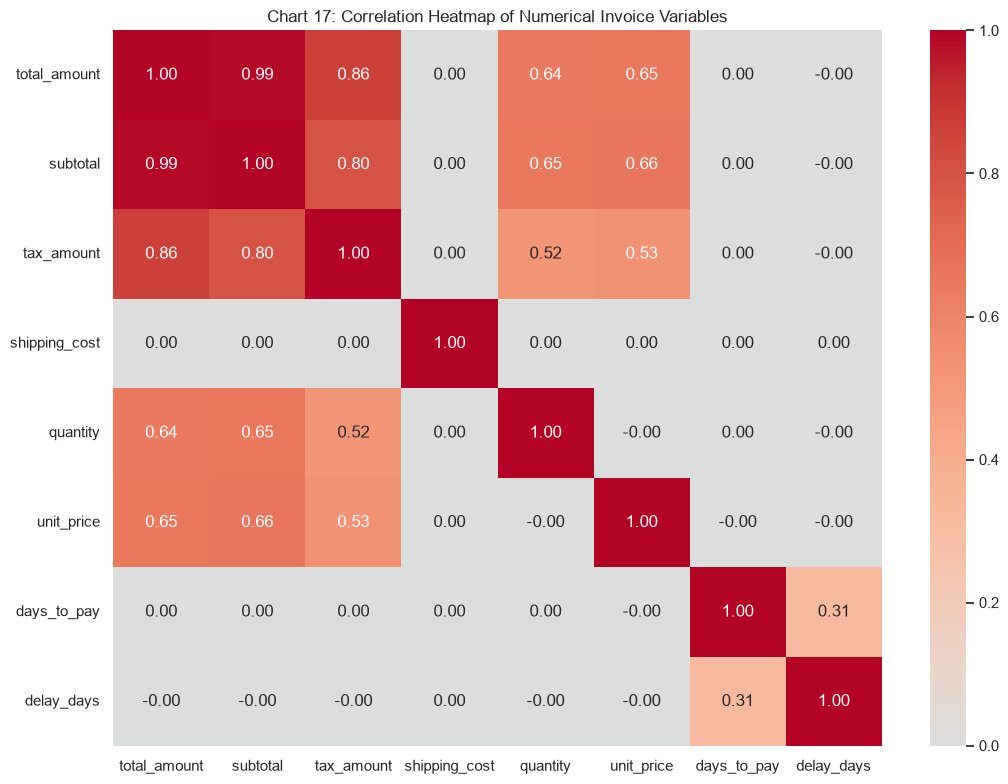

In [26]:
corr_cols = [
    "total_amount", "subtotal", "tax_amount", "shipping_cost",
    "quantity", "unit_price", "days_to_pay", "delay_days"
]
available_corr_cols = [c for c in corr_cols if c in df.columns]
corr_data = df[available_corr_cols].apply(pd.to_numeric, errors="coerce")
correlation = corr_data.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Chart 17: Correlation Heatmap of Numerical Invoice Variables")
plt.tight_layout()
plt.show()


## 11. Insights and ML hypotheses – generate evidence to review

In [27]:
print("INSIGHT CHECKLIST – interpret the computed outputs before writing the final report")
print("1. Invoice amount distribution: use Chart 1 and Chart 4 to identify skew and outliers.")
print("   ML hypothesis: invoice amount, quantity and discount may help predict cash-flow exposure.")
print("2. Days-to-pay distribution: use Chart 2 to describe customer payment speed.")
print("   ML hypothesis: customer history and invoice characteristics may predict days to pay.")
print("3. Paid delay distribution: use Chart 3 and Chart 6. Positive values indicate actual late payments.")
print("   ML hypothesis: payment terms and customer history may predict late-payment probability.")
print("4. Monthly invoice volume: use Chart 8 to identify demand / billing seasonality.")
print("   ML hypothesis: invoice month may improve invoice-volume and cash-flow forecasts.")
print("5. Monthly paid delay: use Chart 9 to detect changes in payment behaviour over time.")
print("   ML hypothesis: month and customer history may help forecast payment delay.")
print("6. Customer concentration: use Charts 11 and 14 to separate late-paid behaviour from overdue balances.")
print("   ML hypothesis: repeated past-due invoices may help identify customer credit risk.")
print("7. Aging exposure: use Charts 12 and 13 to identify where outstanding balances are concentrated.")
print("   ML hypothesis: invoice age, amount and customer history may predict collection priority.")
print("8. Country differences: use Chart 15 only if country coverage is sufficient.")
print("   ML hypothesis: country-level patterns may add predictive signal, subject to data validation.")
print("9. Repeat-customer behaviour: use Chart 16 to assess recurring billing relationships.")
print("   ML hypothesis: prior invoice count and past-due history may predict future collection risk.")
print("10. Numeric relationships: use Chart 17 to inspect associations, not causal effects.")
print("    ML hypothesis: selected non-leaking numerical features may improve model performance.")

print("\nDATA LIMITATION:")
print("The supplied Week 1 outputs indicate zero paid invoices with positive delay.")
print("Therefore, a supervised late-payment classifier cannot be meaningfully trained")
print("until genuine positive late-paid examples are present and the status/date inconsistency is resolved.")


INSIGHT CHECKLIST – interpret the computed outputs before writing the final report
1. Invoice amount distribution: use Chart 1 and Chart 4 to identify skew and outliers.
   ML hypothesis: invoice amount, quantity and discount may help predict cash-flow exposure.
2. Days-to-pay distribution: use Chart 2 to describe customer payment speed.
   ML hypothesis: customer history and invoice characteristics may predict days to pay.
3. Paid delay distribution: use Chart 3 and Chart 6. Positive values indicate actual late payments.
   ML hypothesis: payment terms and customer history may predict late-payment probability.
4. Monthly invoice volume: use Chart 8 to identify demand / billing seasonality.
   ML hypothesis: invoice month may improve invoice-volume and cash-flow forecasts.
5. Monthly paid delay: use Chart 9 to detect changes in payment behaviour over time.
   ML hypothesis: month and customer history may help forecast payment delay.
6. Customer concentration: use Charts 11 and 14 to se

In [28]:
df.to_csv("week2_eda_dataset.csv", index=False)
aging_count.rename("invoice_count").to_csv("invoice_aging_count.csv")
aging_amount.rename("outstanding_amount").to_csv("invoice_aging_amount.csv")
country_summary.to_csv("country_past_due_summary.csv")
customer_activity.to_csv("customer_activity_summary.csv")

print("Week 2 analysis files saved.")

Week 2 analysis files saved.
